# Fractionally spaced, passband and Nyquist-inband equalization

## 1. Setup

In [1]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. SSE and two-phase FSE design

In [2]:
h = np.array([-0.5, 1.0 + 0.25j, -0.5j])
symbol_energy, snr_mfb = 1.0, 10.0
noise_var = symbol_energy * np.vdot(h, h).real / snr_mfb
zfe = ae.ZFE.fromChannel(h, n_taps=129, n_fft=16384)
mmse_le = ae.MMSELE.fromChannel(h, snr_mfb=snr_mfb, n_taps=129, n_fft=16384)
g_index, g = ae.sampledPulse(h, oversampling=2, span_symbols=24, timing_offset=0.19, rolloff=0.0)
common = dict(oversampling=2, symbol_energy=symbol_energy, noise_var=noise_var, n_taps=81, n_fft=16384)
mmse_fse = ae.MMSEFSE.fromPulse(g_index, g, **common)
zf_fse = ae.ZFFSE.fromPulse(g_index, g, **common)
identity_rhs = 2 * mmse_fse.h_norm**2 * mmse_fse.qBins()
assert np.allclose(mmse_fse.s_bins, identity_rhs)
assert np.isclose(mmse_fse.idealMse(), mmse_fse.matchedReferenceMse(), rtol=1e-12)
print("SSE: ZF noise variance / MMSE MSE:", zfe.outputNoiseVariance(noise_var), mmse_le.mse(1, noise_var))
print("FSE ideal / matched reference:", mmse_fse.idealMse(), mmse_fse.matchedReferenceMse())

SSE: ZF noise variance / MMSE MSE: 0.24509803921568632 0.17605075349359248
FSE ideal / matched reference: 0.17650946778579465 0.17650946778579465


## 3. High-rate data and fixed-model evaluation

MMSE-FSE measured MSE: 0.17600348305409075 finite-model: {'alpha_real': 0.8234905322142054, 'alpha_imag': 4.5102810375396984e-17, 'bias': 0.031155592218024452, 'residual_isi': 0.016149420813697635, 'filtered_noise': 0.12932483826192334, 'mse': 0.17662985129364545}
ZF-FSE measured MSE: 0.24976902483796762 finite-model: {'alpha_real': 1.0000000000000002, 'alpha_imag': -4.889751797909625e-17, 'bias': 5.169477384082928e-32, 'residual_isi': 0.00014888096560250474, 'filtered_noise': 0.2456107543595933, 'mse': 0.2457596353251958}


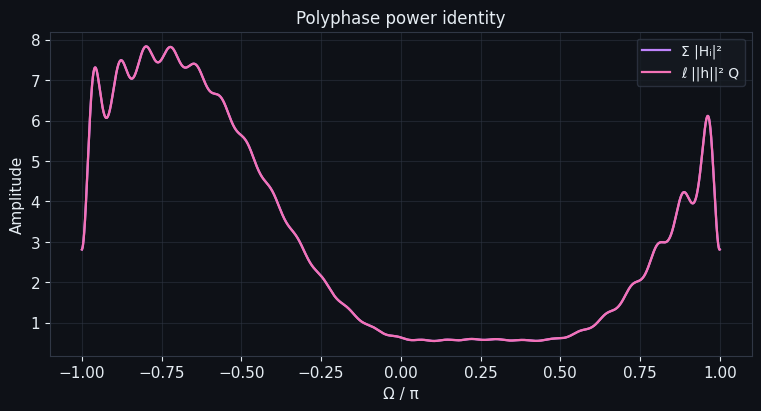

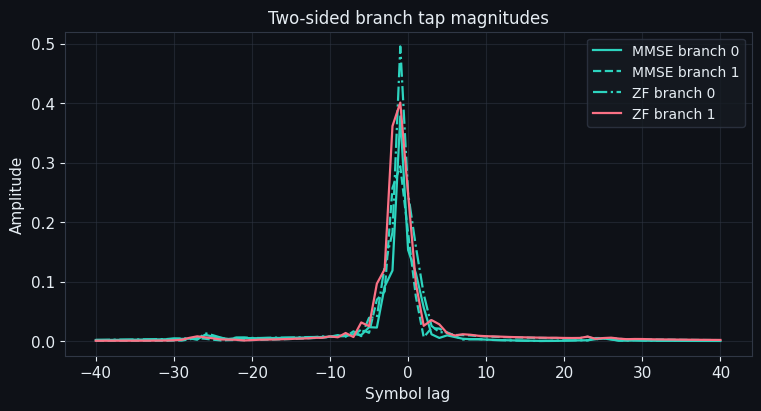

Model                                  Tail MSE     Tail MSD  Update rate
MMSE-FSE                                0.17406            —            —
ZF-FSE                                  0.24581            —            —


In [3]:
batch = data.pulse_channel(6000, rng=np.random.default_rng(3504), g_index=g_index, g=g, oversampling=2,
                           symbol_energy=1.0, noise_var=noise_var)
results = {
  label: training.evaluate(model, batch, name=label, guard=180)
  for label, model in (("MMSE-FSE", mmse_fse), ("ZF-FSE", zf_fse))
}
for label, model in (("MMSE-FSE", mmse_fse), ("ZF-FSE", zf_fse)):
  print(label, "measured MSE:", np.mean(results[label].mse[results[label].valid]), "finite-model:", model.finiteError())
freq = np.fft.fftshift(2 * np.fft.fftfreq(mmse_fse.n_fft))
plot.lines({
  "Σ |Hᵢ|²": np.fft.fftshift(mmse_fse.s_bins),
  "ℓ ||h||² Q": np.fft.fftshift(identity_rhs)
}, x=freq, xlabel="Ω / π", title="Polyphase power identity")
plot.show()
plot.lines(
  {
    f"{label} branch {i}": np.abs(model.w_branch[i])
    for label, model in (("MMSE", mmse_fse), ("ZF", zf_fse))
    for i in range(2)
  }, x=mmse_fse.w_index, xlabel="Symbol lag", title="Two-sided branch tap magnitudes")
plot.show()
training.summary(results, tail=3000)

## 4. Passband equivalence

In [4]:
oversampling, carrier, n_symbols = 8, 0.18, 5000
g_index_ib, g_ib = ae.sampledPulse(h, oversampling, span_symbols=11, rolloff=0.35)
fse_ib = ae.MMSEFSE.fromPulse(g_index_ib, g_ib, oversampling=oversampling, symbol_energy=1.0, noise_var=0.006,
                              n_taps=31, n_fft=8192)
clean_batch = data.pulse_channel(n_symbols, rng=np.random.default_rng(3505), g_index=g_index_ib, g=g_ib,
                                 oversampling=oversampling, noise_var=0.0)
rf_real, analytic_ideal = ae.complexToPassband(clean_batch.x, carrier)
base = training.evaluate(fse_ib, clean_batch, name="Baseband FSE", guard=150)
passband_output = ae.passbandEquivalentOutput(fse_ib, analytic_ideal, carrier, n_symbols)
difference = np.max(np.abs(base.y[base.valid] - passband_output[base.valid]))
print(f"Passband/baseband maximum difference: {difference:.3e}")
assert difference < 1e-9

Passband/baseband maximum difference: 7.747e-12


## 5. Four-path inband training and held-out evaluation

Held-out baseband MSE: 4.695109497521616e-05 symmetry mismatch: 1.7099689443176207


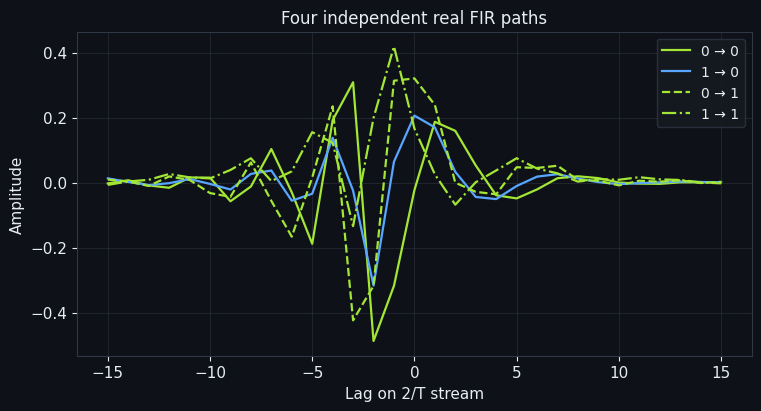

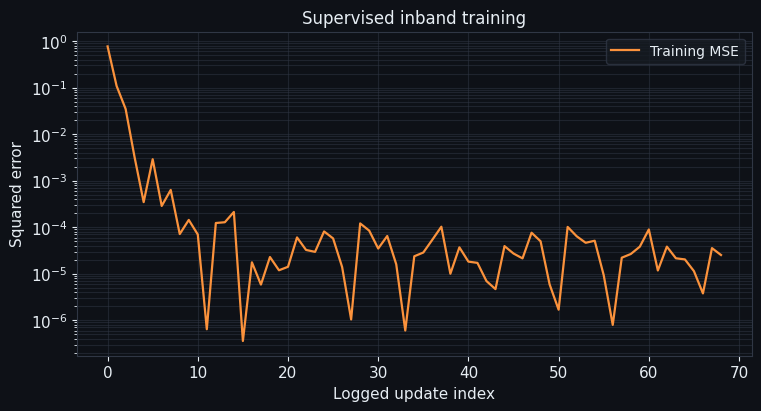

Model                                  Tail MSE     Tail MSD  Update rate
Nyquist inband                       4.6944e-05            —            —


In [5]:
recovered = ae.analyticFromReal(rf_real)
i_stream, q_stream = ae.splitStaggeredStreams(recovered, oversampling, i_gain=1.12, q_gain=0.78, i_leak=0.10,
                                              q_leak=-0.13)
k = np.arange(n_symbols)
desired_passband = clean_batch.d * np.exp(2j * np.pi * carrier * oversampling * k)
inband = ae.NyquistInband(n_taps=31, step_size=0.42)
result = training.fit_inband(inband, i_stream, q_stream, desired_passband, start=140, stop=3200, epochs=3)
output_baseband = ae.demodulateSymbols(result.y, carrier, oversampling)
held_mse = np.mean(np.abs(clean_batch.d[result.valid] - output_baseband[result.valid])**2)
print("Held-out baseband MSE:", held_mse, "symmetry mismatch:", inband.symmetryMismatch())
plot.lines({f"{i} → {o}": inband.w[o, i]
            for o in range(2)
            for i in range(2)}, x=inband.w_index, xlabel="Lag on 2/T stream", title="Four independent real FIR paths")
plot.show()
plot.lines({"Training MSE": result.extras["training_mse"]}, scale="log", xlabel="Logged update index",
           ylabel="Squared error", title="Supervised inband training")
plot.show()
training.summary({result.name: result}, tail=1000)